In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TITLE",
        "NAICS",
        "OCC_CODE",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP"
    ]
)

print("Dataset loaded successfully!")
print(df.shape)
df.head()

In [1]:
print("Jupyter is working")


Jupyter is working


In [2]:
import pandas as pd

df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    nrows=100
)

print(df.shape)
df.head()

(100, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [3]:
df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TITLE",
        "NAICS",
        "OCC_CODE",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP"
    ]
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(413327, 6)


In [4]:
selected_occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists",
    "Information Security Analysts",
    "Computer Programmers"
]

pie_data = df[
    (df["AREA_TITLE"] == "U.S.") &
    (df["NAICS"].astype(str).isin(["0", "000000"])) &
    (df["O_GROUP"] == "detailed") &
    (df["OCC_TITLE"].isin(selected_occupations))
].copy()

pie_data["TOT_EMP"] = pd.to_numeric(
    pie_data["TOT_EMP"], errors="coerce"
)

print(pie_data[["OCC_TITLE", "TOT_EMP"]])

                                        OCC_TITLE  TOT_EMP
136                 Information Security Analysts   175350
138  Computer and Information Research Scientists    35210
148                          Computer Programmers   120370
149                           Software Developers  1656880
165                               Data Scientists   192710


In [5]:
df[
    (df["AREA_TITLE"] == "U.S.") &
    (df["OCC_TITLE"].str.contains("Data Scientist", case=False, na=False))
][["NAICS", "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP"]].head(15)

,NAICS,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP
164,000000,15-2050,Data Scientists,broad,192710
165,000000,15-2051,Data Scientists,detailed,192710
1562,000001,15-2050,Data Scientists,broad,184720
1563,000001,15-2051,Data Scientists,detailed,184720
3222,21,15-2050,Data Scientists,broad,360
3223,21,15-2051,Data Scientists,detailed,360
3750,22,15-2050,Data Scientists,broad,810
3751,22,15-2051,Data Scientists,detailed,810
4278,23,15-2050,Data Scientists,broad,440
4279,23,15-2051,Data Scientists,detailed,440


In [6]:
pie_data = pie_data.dropna(subset=["TOT_EMP"])

pie_data["Percentage"] = (
    pie_data["TOT_EMP"] / pie_data["TOT_EMP"].sum() * 100
)

print(
    pie_data[["OCC_TITLE", "TOT_EMP", "Percentage"]]
    .sort_values("TOT_EMP", ascending=False)
    .to_string(index=False)
)

                                   OCC_TITLE  TOT_EMP  Percentage
                         Software Developers  1656880   75.985545
                             Data Scientists   192710    8.837800
               Information Security Analysts   175350    8.041660
                        Computer Programmers   120370    5.520243
Computer and Information Research Scientists    35210    1.614752


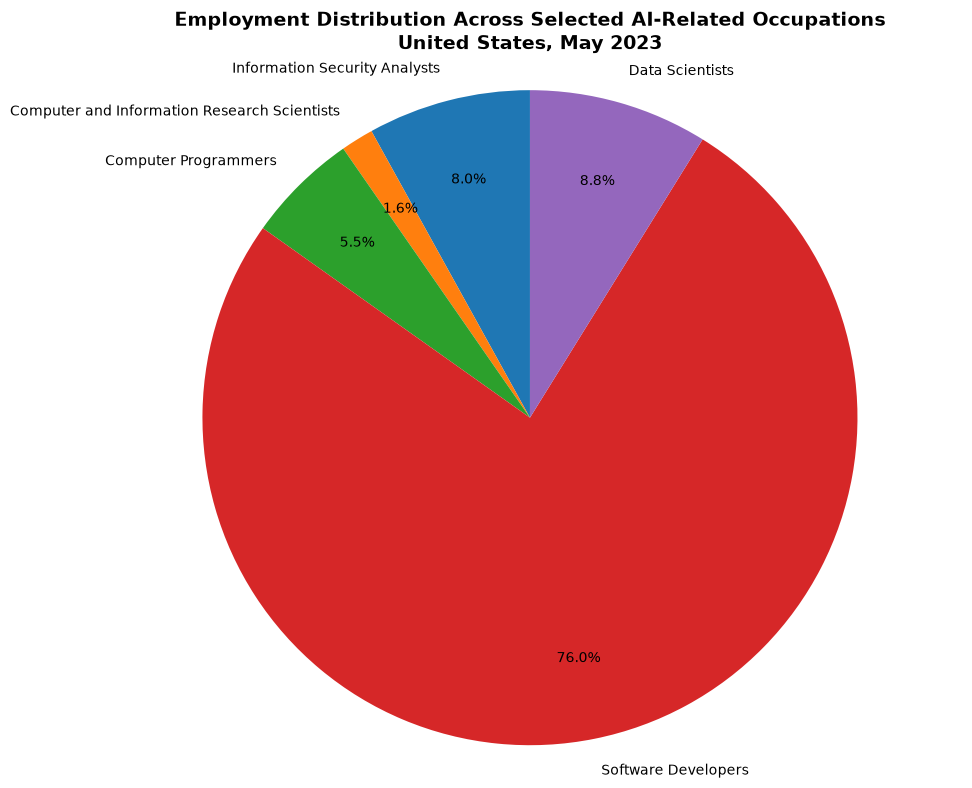

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.pie(
    pie_data["TOT_EMP"],
    labels=pie_data["OCC_TITLE"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75
)

plt.title(
    "Employment Distribution Across Selected AI-Related Occupations\n"
    "United States, May 2023",
    fontsize=14,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

In [8]:
salary_df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TITLE",
        "NAICS",
        "OCC_TITLE",
        "O_GROUP",
        "A_MEAN"
    ]
)

print("Salary data loaded successfully!")
print(salary_df.shape)

Salary data loaded successfully!
(413327, 5)


In [9]:
salary_data = salary_df[
    (salary_df["AREA_TITLE"] == "U.S.") &
    (salary_df["NAICS"].astype(str).isin(["0", "000000"])) &
    (salary_df["O_GROUP"] == "detailed") &
    (salary_df["OCC_TITLE"].isin(selected_occupations))
].copy()

salary_data["A_MEAN"] = pd.to_numeric(
    salary_data["A_MEAN"],
    errors="coerce"
)

salary_data = salary_data.dropna(subset=["A_MEAN"])
salary_data = salary_data.sort_values("A_MEAN")

print(salary_data[["OCC_TITLE", "A_MEAN"]])

                                        OCC_TITLE  A_MEAN
148                          Computer Programmers  107750
165                               Data Scientists  119040
136                 Information Security Analysts  124740
149                           Software Developers  138110
138  Computer and Information Research Scientists  157160


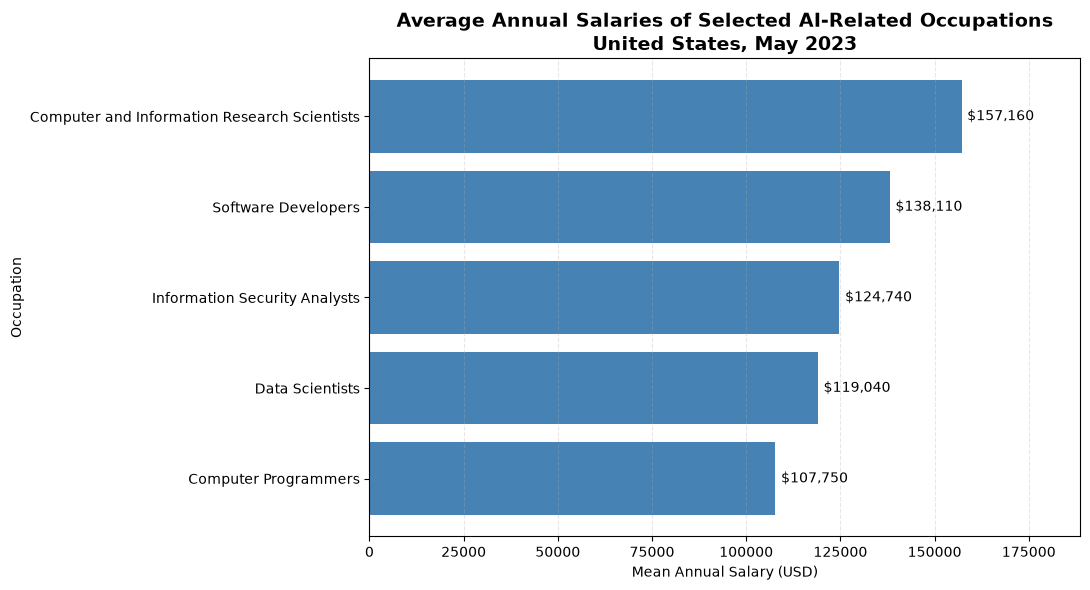

In [11]:
plt.figure(figsize=(11, 6))

bars = plt.barh(
    salary_data["OCC_TITLE"],
    salary_data["A_MEAN"],
    color="steelblue"
)
plt.xlabel("Mean Annual Salary (USD)")
plt.ylabel("Occupation")
plt.title(
    "Average Annual Salaries of Selected AI-Related Occupations\n"
    "United States, May 2023",
    fontsize=14,
    fontweight="bold"
)
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1500,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center"
    )
plt.xlim(0, salary_data["A_MEAN"].max() * 1.2)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()